In [1]:
from typing import Annotated

from typing_extensions import TypedDict

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

In [2]:
class State(TypedDict):
    messages:Annotated[list, add_messages]
    
graph_builder = StateGraph(State)

In [3]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [4]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model


llm = init_chat_model("groq:openai/gpt-oss-120b")

In [5]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.0', 'langchain': '1.5.0'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000002BA5A7AA900>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000002BA5A7AB380>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [6]:
## Node functionality
def chatbot(state:State):
    return {"messages": [llm.invoke(state["messages"])]}
                                          

In [7]:
graph_builder=StateGraph(State)
## Adding node
graph_builder.add_node("llmchatbot",chatbot)
## Adding edges
graph_builder.add_edge(START,"llmchatbot")

graph_builder.add_edge("llmchatbot",END)

graph= graph_builder.compile()


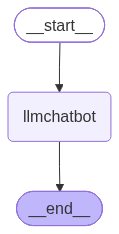

In [8]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
    
except Exception as e:
    print(f"Error rendering diagram: {e}")

In [9]:
response=graph.invoke({"messages":"Hi"})
response

{'messages': [HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='635a38f9-2078-44d5-8817-d53c47622f6b'),
  AIMessage(content='Hello! How can I assist you today?', additional_kwargs={'reasoning_content': 'User says "Hi". Need to respond politely. No policy issues.'}, response_metadata={'token_usage': {'completion_tokens': 33, 'prompt_tokens': 72, 'total_tokens': 105, 'completion_time': 0.068750036, 'completion_tokens_details': {'reasoning_tokens': 15}, 'prompt_time': 0.004618371, 'prompt_tokens_details': None, 'queue_time': 0.138428655, 'total_time': 0.073368407}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_dee443f41b', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1dfd7-3481-7761-8023-638c81e873ef-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 33, 'total_tokens': 105, 'output_token_details': {'reasoning': 15}})]}

In [10]:
response["messages"][-1].content

'Hello! How can I assist you today?'

In [11]:
for event in graph.stream({"messages":"Hi How are you?"}):
    for value in event.values():
        print(value["messages"][-1].content)
    

Hello! I'm doing great, thanks for asking. How can I help you today?


## Chat with Tavily

In [12]:
from langchain_tavily import TavilySearch

tool= TavilySearch(max_results=2)

tool.invoke("What is the Langgraph?")

{'query': 'What is the Langgraph?',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.ibm.com/think/topics/langgraph',
   'title': 'What is LangGraph? | IBM',
   'content': 'LangGraph, created by LangChain, is an open source AI agent framework designed to build, deploy and manage complex generative AI agent workflows. It provides a set of tools and libraries that enable users to create, run and optimize large language models (LLMs) in a scalable and efficient manner. At its core, LangGraph uses the power of graph-based architectures to model and manage the intricate relationships between various components of an AI agent workflow. [...] LangGraph illuminates the processes within an AI workflow, allowing full transparency of the agent’s state. Within LangGraph, the “state” feature serves as a memory bank that records and tracks all the valuable information processed by the AI system. It’s similar to a digital notebook where the system captur

In [27]:
## Custom Function

def multiply(a:int,b:int)->int:
    """Multiply a and b

    Args:
        a (int): first int
        b (int): second int

    Returns:
        int: output int
    """
    return a*b

In [35]:
tools = [tool, multiply]

In [36]:
llm_with_tools=llm.bind_tools(tools)

llm_with_tools

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.0', 'langchain': '1.5.0'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000002BA5A7AA900>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000002BA5A7AB380>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, an

In [38]:
## Stategraph

from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node Definition
def tool_calling_llm(state:State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

## Graph
builder= StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## adding Edges
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges("tool_calling_llm",
                              ## If the latest message is a tool call, then go to the tools node
                              ## If the latest message is a NOT a tool call, then go to the END node
                              tools_condition
                              )

builder.add_edge("tools", END)

## compile the graph
graph=builder.compile()



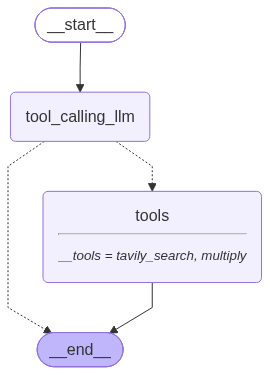

In [39]:

display(Image(graph.get_graph().draw_mermaid_png()))
    


In [40]:
response= graph.invoke({"messages":"What is the recent AI news?"})

In [22]:
response["messages"][-1].content

'{"query": "AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.instagram.com/p/Dfeapc_smyY", "title": "Instagram", "content": "aiedgeinsightscom\'s profile picture\\n\\naiedgeinsightscom\\n\\n🚀 \\\\\\\\AI News Today | November 8, 2026\\\\\\\\  \\n  \\nThe AI landscape is changing fast. Here are today\'s key topics:  \\n  \\n🧠 Anthropic research and AI-powered productivity   \\n🌍 Google Genie 4 and interactive AI worlds   \\n🔐 AI safety and independent oversight   \\n🤖 Robotics and the future of intelligent systems   \\n📊 AI regulation, data centres, and investment trends   \\n  \\nAI is creating exciting opportunities, but responsible development matters just as much.  \\n  \\nFollow \\\\\\\\@AI Edge Insights\\\\\\\\ for the latest AI news, trends, and insights.  \\n  \\n🌐 Visit:   \\n  \\n#AINewsToday #ArtificialIntelligence #AIUpdates #Anthropic #GoogleGenie4 #AISafety #Robotics #TechNews #AIInnovation #AIEdgeInsights\\

In [24]:
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is the recent AI news?
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_ac35b7de-a48a-48b4-9c66-d6c473957a89)
 Call ID: fc_ac35b7de-a48a-48b4-9c66-d6c473957a89
  Args:
    query: AI news November 2026
    search_depth: advanced
    time_range: month
================================= Tool Message =================================
Name: tavily_search

{"query": "AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.instagram.com/p/Dfeapc_smyY", "title": "Instagram", "content": "aiedgeinsightscom's profile picture\n\naiedgeinsightscom\n\n🚀 \\\\AI News Today | November 8, 2026\\\\  \n  \nThe AI landscape is changing fast. Here are today's key topics:  \n  \n🧠 Anthropic research and AI-powered productivity   \n🌍 Google Genie 4 and interactive AI worlds   \n🔐 AI safety and independe

In [48]:
response= graph.invoke({"messages":"Give me recent AI news and then multiply 5 by 8"})

response["messages"][-1].content



'{"query": "AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.instagram.com/p/Dfeapc_smyY", "title": "Instagram", "content": "aiedgeinsightscom\'s profile picture\\n\\naiedgeinsightscom\\n\\n🚀 \\\\\\\\AI News Today | November 8, 2026\\\\\\\\  \\n  \\nThe AI landscape is changing fast. Here are today\'s key topics:  \\n  \\n🧠 Anthropic research and AI-powered productivity   \\n🌍 Google Genie 4 and interactive AI worlds   \\n🔐 AI safety and independent oversight   \\n🤖 Robotics and the future of intelligent systems   \\n📊 AI regulation, data centres, and investment trends   \\n  \\nAI is creating exciting opportunities, but responsible development matters just as much.  \\n  \\nFollow \\\\\\\\@AI Edge Insights\\\\\\\\ for the latest AI news, trends, and insights.  \\n  \\n🌐 Visit:   \\n  \\n#AINewsToday #ArtificialIntelligence #AIUpdates #Anthropic #GoogleGenie4 #AISafety #Robotics #TechNews #AIInnovation #AIEdgeInsights\\

In [49]:
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Give me recent AI news and then multiply 5 by 8
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_f8912b15-2339-430b-9a38-592b4458929e)
 Call ID: fc_f8912b15-2339-430b-9a38-592b4458929e
  Args:
    query: AI news November 2026
    search_depth: advanced
    time_range: month
================================= Tool Message =================================
Name: tavily_search

{"query": "AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.instagram.com/p/Dfeapc_smyY", "title": "Instagram", "content": "aiedgeinsightscom's profile picture\n\naiedgeinsightscom\n\n🚀 \\\\AI News Today | November 8, 2026\\\\  \n  \nThe AI landscape is changing fast. Here are today's key topics:  \n  \n🧠 Anthropic research and AI-powered productivity   \n🌍 Google Genie 4 and interactive AI worlds   \n🔐 AI 

### ReAct based architecture

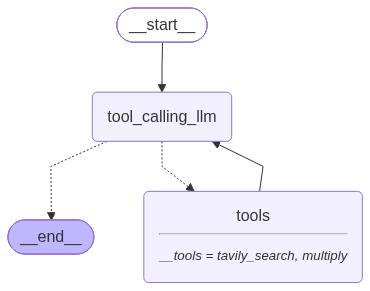

In [50]:

from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node Definition
def tool_calling_llm(state:State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

## Graph
builder= StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## adding Edges
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges("tool_calling_llm",
                              ## If the latest message is a tool call, then go to the tools node
                              ## If the latest message is a NOT a tool call, then go to the END node
                              tools_condition
                              )

builder.add_edge("tools", "tool_calling_llm")

graph=builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

In [51]:
response= graph.invoke({"messages":"Give me recent AI news and then multiply 5 by 8"})

response["messages"][-1].content

'**Recent AI News (Late\u202fNovember\u202f2026)**  \n\n| Date / Source | Headline & Key Points | Why It Matters |\n|---------------|-----------------------|----------------|\n| **Nov\u202f12\u202f2026 – “AI News – Mid‑November 2026” (YouTube/Enterprise AI Show)** | • **NVIDIA CEO Jensen\u202fHuang resigns** amid reports of an alleged GPU pipeline to China and internal controversy. <br>• Discussion of possible successors (Colette\u202fKress, Tim\u202fCook, Lisa\u202fSu, Andy\u202fJassy, Lip‑Bu\u202fTan, René\u202fHaas). <br>• Anthropic prepares for an IPO, signaling continued market appetite for large‑model firms. | • Leadership change at NVIDIA could shift the direction of GPU supply, pricing, and AI‑hardware roadmaps. <br>• A new Anthropic IPO adds another major player to public markets, affecting investor sentiment in the generative‑AI sector. |\n| **Nov\u202f9\u202f2026 – “AI\u202fUnlocked: 4 Essential Things to Know This Week” (SHRM)** | • **U.S. midterm voters approve local bans 

In [52]:
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Give me recent AI news and then multiply 5 by 8
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_3ab1a782-0d80-4512-b5d1-6784cf69c41f)
 Call ID: fc_3ab1a782-0d80-4512-b5d1-6784cf69c41f
  Args:
    query: latest AI news November 2026
    search_depth: advanced
    time_range: week
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.youtube.com/watch?v=IeFDTftW2tA", "title": "AI News - Mid-November 2026", "content": "Brian and Brandon discuss the stunning resignation of NVIDIA CEO Jensen Huang, a story big enough to push election results, Anthropic's IPO news, and a week of earnings off the agenda. They walk through what has been reported so far: relationships, in

## Adding Memory in Agentic Greaph

In [53]:
response= graph.invoke({"messages":"My Name is John"})
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

My Name is John
================================== Ai Message ==================================

Nice to meet you, John! How can I assist you today?


In [54]:
response= graph.invoke({"messages":"What is my name"})
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is my name
================================== Ai Message ==================================

I don’t actually know your name—unless you’ve shared it with me before, I don’t have that information. If you’d like me to address you by name, just let me know what it is!


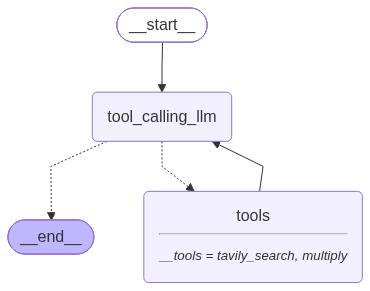

In [55]:

from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

## Node Definition
def tool_calling_llm(state:State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

## Graph
builder= StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## adding Edges
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges("tool_calling_llm",
                              ## If the latest message is a tool call, then go to the tools node
                              ## If the latest message is a NOT a tool call, then go to the END node
                              tools_condition
                              )

builder.add_edge("tools", "tool_calling_llm")

graph=builder.compile(checkpointer=memory)
display(Image(graph.get_graph().draw_mermaid_png()))

In [57]:
config={"configurable":{"thread_id":"1"}}

response= graph.invoke({"messages":"My Name is John"},config=config)
response

{'messages': [HumanMessage(content='My Name is John', additional_kwargs={}, response_metadata={}, id='8d1a8250-da5a-406f-b31d-9434fe9702d1'),
  AIMessage(content='Nice to meet you, John! How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "My Name is John". Likely they want a response acknowledging. No request. Just respond.'}, response_metadata={'token_usage': {'completion_tokens': 47, 'prompt_tokens': 346, 'total_tokens': 393, 'completion_time': 0.097779262, 'completion_tokens_details': {'reasoning_tokens': 24}, 'prompt_time': 0.023694671, 'prompt_tokens_details': None, 'queue_time': 0.17056304, 'total_time': 0.121473933}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_c800245357', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1dffc-f0bb-75bd-8123-a78760423ca1-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 346, 'output_tokens': 47, 'total_token

In [58]:
response['messages'][-1].content

'Nice to meet you, John! How can I help you today?'

In [59]:

response= graph.invoke({"messages":"What is my name"},config=config)
print(response['messages'][-1].content)

Your name is John.


In [60]:
response= graph.invoke({"messages":"Do you remember my name"},config=config)
print(response['messages'][-1].content)

Yes—I remember you told me your name is **John**. How can I assist you today?


In [61]:
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

In [62]:
def superbot(state:State):
    return {"messages": [llm.invoke(state["messages"])]}

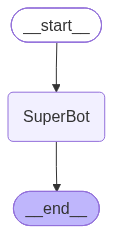

In [63]:
graph = StateGraph(State)

## node
graph.add_node("SuperBot", superbot)

## edges

graph.add_edge(START, "SuperBot")
graph.add_edge("SuperBot", END)

graph_builder=graph.compile(checkpointer=memory)

## Display

from IPython.display import Image, display
display(Image(graph_builder.get_graph().draw_mermaid_png()))


In [64]:
## invocation

config = {"configurable": {"thread_id":"1"}}

graph_builder.invoke({'messages':'My name is John and I like Tennis'}, config)

{'messages': [HumanMessage(content='My name is John and I like Tennis', additional_kwargs={}, response_metadata={}, id='4b16f0d1-7cdb-46a4-aae6-9bab71734218'),
  AIMessage(content='Nice to meet you, John! 🎾  \nTennis is a great sport—whether you enjoy watching the pros or playing on the court yourself. Do you have a favorite player or a particular aspect of the game you love most?', additional_kwargs={'reasoning_content': 'The user says "My name is John and I like Tennis". Likely they just want a response acknowledging. There\'s no question. We can respond friendly, maybe ask about favorite player, etc. No disallowed content.'}, response_metadata={'token_usage': {'completion_tokens': 101, 'prompt_tokens': 79, 'total_tokens': 180, 'completion_time': 0.210565819, 'completion_tokens_details': {'reasoning_tokens': 45}, 'prompt_time': 0.003384532, 'prompt_tokens_details': None, 'queue_time': 0.147162598, 'total_time': 0.213950351}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 

## Streaming


Methods: stream() and astream() 
    # These methods are sync and async methods for streaming back results

Additional parameters in streaming modes for graph state:

        values : This streams the full state of the graph after each node is called.

        updates : This streams updates to the state of the graph after each node is called.


### invocation
#### Stream mode is Update
#### Only AI message gets

In [67]:
## invocation
## Stream mode is Update
## Only AI message gets displayed
config = {"configurable": {"thread_id":"3"}}

for chunk in graph_builder.stream({'messages':'Hi, My name is John and I like Tennis'}, config, stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Got it, John! 🎾  \nIf you’d like to chat about tennis—whether it’s your favorite players, techniques you’re practicing, upcoming tournaments, or anything else—just let me know. I’m here to talk tennis (or anything else you’re interested in)!', additional_kwargs={'reasoning_content': 'The user repeats the same phrase. Possibly they expect a different response? Could be they want a simple acknowledgement. Should respond politely, maybe ask a question. Keep conversation.'}, response_metadata={'token_usage': {'completion_tokens': 100, 'prompt_tokens': 202, 'total_tokens': 302, 'completion_time': 0.213001846, 'completion_tokens_details': {'reasoning_tokens': 35}, 'prompt_time': 0.053915383, 'prompt_tokens_details': None, 'queue_time': 0.174696318, 'total_time': 0.266917229}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_854fa9be4c', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}

#### invocation
#### Stream mode is Update
#### Human messages get displayed with entire messages.


In [73]:
## invocation
## Stream mode is Update
## Human messages get displayed with entire messages.

config = {"configurable": {"thread_id":"3"}}

for chunk in graph_builder.stream({'messages':'Hi, My name is John and I like Tennis'}, config, stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi, My name is John and I like Tennis', additional_kwargs={}, response_metadata={}, id='77f4d200-b175-48fb-a00d-68d2bcb46ac5'), AIMessage(content='Hi John! Nice to meet you. 🎾  \nHow long have you been playing tennis? Do you have a favorite player or a go‑to shot you love to work on?', additional_kwargs={'reasoning_content': 'We need to respond. The user just says "Hi, My name is John and I like Tennis". Probably respond friendly, ask about tennis preferences. No disallowed content. Just a normal chat.'}, response_metadata={'token_usage': {'completion_tokens': 87, 'prompt_tokens': 81, 'total_tokens': 168, 'completion_time': 0.182978318, 'completion_tokens_details': {'reasoning_tokens': 41}, 'prompt_time': 0.003547799, 'prompt_tokens_details': None, 'queue_time': 0.221866146, 'total_time': 0.186526117}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_c3da0d4bb9', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'm

In [69]:
config = {"configurable": {"thread_id":"4"}}

for chunk in graph_builder.stream({'messages':'Hi, My name is John and I like Tennis'}, config, stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Hello John! Nice to meet you. 🎾  \nIt’s great to hear you’re into tennis—whether you’re a player, a fan, or both, there’s always something exciting happening on the court. How can I help you today? Maybe you’re looking for tips to improve your game, news about the latest tournaments, or just want to chat about your favorite players? Let me know!', additional_kwargs={'reasoning_content': 'The user says: "Hi, My name is John and I like Tennis". Likely a greeting. We should respond friendly, ask about tennis, perhaps ask how we can help. No policy issues.'}, response_metadata={'token_usage': {'completion_tokens': 132, 'prompt_tokens': 81, 'total_tokens': 213, 'completion_time': 0.281061465, 'completion_tokens_details': {'reasoning_tokens': 42}, 'prompt_time': 0.029685352, 'prompt_tokens_details': None, 'queue_time': 0.209924828, 'total_time': 0.310746817}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_02b0d31eca', 'service_tie

In [70]:
for chunk in graph_builder.stream({'messages':'I also like football'}, config, stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi, My name is John and I like Tennis', additional_kwargs={}, response_metadata={}, id='3a4d59a5-cef2-4774-ad4d-27699650d753'), AIMessage(content='Hello John! Nice to meet you. 🎾  \nIt’s great to hear you’re into tennis—whether you’re a player, a fan, or both, there’s always something exciting happening on the court. How can I help you today? Maybe you’re looking for tips to improve your game, news about the latest tournaments, or just want to chat about your favorite players? Let me know!', additional_kwargs={'reasoning_content': 'The user says: "Hi, My name is John and I like Tennis". Likely a greeting. We should respond friendly, ask about tennis, perhaps ask how we can help. No policy issues.'}, response_metadata={'token_usage': {'completion_tokens': 132, 'prompt_tokens': 81, 'total_tokens': 213, 'completion_time': 0.281061465, 'completion_tokens_details': {'reasoning_tokens': 42}, 'prompt_time': 0.029685352, 'prompt_tokens_details': None, 'queue

## Streaming in the Async Mode

In [72]:
config = {"configurable": {"thread_id":"5"}}

async for event in graph_builder.astream_events({'messages':'Hi, My name is John and I like Tennis'}, config, version="v2"):
    print(event)

{'event': 'on_chain_start', 'data': {'input': {'messages': 'Hi, My name is John and I like Tennis'}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a1e012-fded-7287-9975-5479ae20577b', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='Hi, My name is John and I like Tennis', additional_kwargs={}, response_metadata={}, id='098add94-398a-42ab-95d1-d76d12e2786f')]}}, 'name': 'SuperBot', 'tags': ['graph:step:1'], 'run_id': '01a1e012-fdf0-735d-b393-1ee8e2efb989', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph', 'langgraph_step': 1, 'langgraph_node': 'SuperBot', 'langgraph_triggers': ('branch:to:SuperBot',), 'langgraph_path': ('__pregel_pull', 'SuperBot'), 'langgraph_checkpoint_ns': 'SuperBot:1ccaef4a-fc5e-3136-5774-5d21713421cb'}, 'parent_ids': ['01a1e012-fded-7287-9975-5479ae20577b']}
{'event': 'on_chat_model_start', 'data': {'input': {'messages': [[HumanMessage(cont